# Exploration of the HR extracts

TechNova Partners faces unusually high attrition, and the HR team wants to understand the potential causes of resignations. In this notebook we inspect, clean and join the three HR extracts, then explore how leavers differ from stayers.

## 0. Setup

### 0.1 Libraries, constants and data

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.figsize": (8, 4.5),
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Target column, with English labels for charts only (the data keep "Oui" and "Non")
TARGET = "a_quitte_l_entreprise"
TARGET_LABELS = {"Oui": "Left", "Non": "Stayed"}
TARGET_COLORS = {"Left": "#d95f02", "Stayed": "#9e9e9e"}

# Neutral color of the bars that show a leaving rate
RATE_BAR_COLOR = "#4c78a8"

# Natural order of the text values that sorting by name would scramble
CATEGORY_ORDERS = {"frequence_deplacement": ["Aucun", "Occasionnel", "Fréquent"]}

# Readable English labels of the explanatory columns, for chart titles and tables
COLUMN_LABELS = {
    "age": "Age (years)",
    "genre": "Gender",
    "revenu_mensuel": "Monthly income",
    "statut_marital": "Marital status",
    "departement": "Department",
    "poste": "Job title",
    "nombre_experiences_precedentes": "Number of previous employers",
    "annees_experience_totale": "Total experience (years)",
    "annees_dans_l_entreprise": "Years in the company",
    "annees_dans_le_poste_actuel": "Years in the current role",
    "annees_depuis_la_derniere_promotion": "Years since the last promotion",
    "annees_sous_responsable_actuel": "Years under the current manager",
    "satisfaction_employee_environnement": "Satisfaction with the environment (1-4)",
    "satisfaction_employee_nature_travail": "Satisfaction with the work itself (1-4)",
    "satisfaction_employee_equipe": "Satisfaction with the team (1-4)",
    "satisfaction_employee_equilibre_pro_perso": "Satisfaction with work-life balance (1-4)",
    "note_evaluation_precedente": "Previous performance rating",
    "note_evaluation_actuelle": "Current performance rating",
    "niveau_hierarchique_poste": "Hierarchical level",
    "heures_supplementaires": "Works overtime",
    "augmentation_salaire_precedente": "Last salary raise (%)",
    "nombre_participation_pee": "Employee savings plan participations",
    "nb_formations_suivies": "Training courses taken",
    "distance_domicile_travail": "Commute distance",
    "niveau_education": "Education level",
    "domaine_etude": "Field of study",
    "frequence_deplacement": "Business travel frequency",
}

sirh = pd.read_csv(RAW_DIR / "extrait_sirh.csv")
evaluations = pd.read_csv(RAW_DIR / "extrait_eval.csv")
survey = pd.read_csv(RAW_DIR / "extrait_sondage.csv")

### 0.2 Data helpers

In [2]:
def describe_source(df):
    """Display the shape, the first rows and the numeric and text summaries of a DataFrame."""
    print(df.shape)
    display(df.head(3))
    display(df.describe().T)
    display(df.describe(exclude="number").T)


def to_employee_id(series):
    """Convert an employee key to an integer by dropping the E_ prefix if present."""
    return series.astype(str).str.removeprefix("E_").astype(int)

### 0.3 Plotting helpers

In [3]:
def make_grid(n_panels, panel_height, sharex=False, n_cols=3):
    """Create a grid of n_cols columns with one panel per item, and hide the unused panels."""
    n_rows = math.ceil(n_panels / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(13, panel_height * n_rows),
        sharex=sharex,
        squeeze=False,
        layout="constrained",
    )
    fig.get_layout_engine().set(w_pad=0.25, h_pad=0.25, wspace=0.12, hspace=0.12)
    for ax in axes.flat[n_panels:]:
        ax.set_visible(False)
    return fig, axes.flat[:n_panels]


def plot_boxplots_by_target(df, columns, title):
    """Draw one boxplot panel per column, comparing stayers and leavers."""
    labels = ["Stayed", "Left"]
    status = df[TARGET].map(TARGET_LABELS)
    sizes = {label: int((status == label).sum()) for label in labels}
    fig, axes = make_grid(len(columns), panel_height=3.4)
    for ax, col in zip(axes, columns):
        boxes = ax.boxplot(
            [df.loc[status == label, col] for label in labels],
            patch_artist=True,
            medianprops={"color": "black"},
        )
        for box, label in zip(boxes["boxes"], labels):
            box.set_facecolor(TARGET_COLORS[label])
        ax.set_xticks(
            [1, 2], labels=[f"{label} (n={size:,})" for label, size in sizes.items()]
        )
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.show()


def plot_leaving_rate_by_value(df, columns, title):
    """Draw one panel per column with the leaving rate of each value and its group size."""
    is_leaver = df[TARGET].eq("Oui")
    overall_rate = is_leaver.mean() * 100
    rates = {}
    for col in columns:
        stats = is_leaver.groupby(df[col]).agg(rate="mean", size="size")
        stats["rate"] *= 100
        if col in CATEGORY_ORDERS:
            stats = stats.loc[CATEGORY_ORDERS[col]]
        elif pd.api.types.is_numeric_dtype(df[col]):
            stats = stats.sort_index()
        else:
            stats = stats.sort_values("rate", ascending=False)
        rates[col] = stats

    longest = max(len(stats) for stats in rates.values())
    fig, axes = make_grid(len(columns), panel_height=0.3 * longest + 1.6, sharex=True)
    x_max = max(stats["rate"].max() for stats in rates.values()) * 1.3
    for ax, (col, stats) in zip(axes, rates.items()):
        bars = ax.barh(stats.index.astype(str), stats["rate"], color=RATE_BAR_COLOR)
        ax.bar_label(bars, labels=[f"n={size:,}" for size in stats["size"]], padding=3)
        line = ax.axvline(
            overall_rate,
            color=TARGET_COLORS["Left"],
            linestyle="--",
            linewidth=1,
            label=f"Overall rate ({overall_rate:.0f}%)",
        )
        ax.invert_yaxis()
        ax.set_xlim(0, x_max)
        ax.set_title(COLUMN_LABELS[col], fontsize=10)
        ax.set_xlabel("Leaving rate (%)")
        ax.tick_params(labelbottom=True)
        ax.grid(axis="x")
        ax.grid(axis="y", visible=False)
    # Leave a band at the top for the title and the legend, which sits under the title
    height = fig.get_figheight()
    fig.get_layout_engine().set(rect=(0, 0, 1, 1 - 0.7 / height))
    fig.suptitle(title, y=1, fontsize=14, fontweight="bold")
    fig.legend(
        handles=[line], loc="upper center", bbox_to_anchor=(0.5, 1 - 0.4 / height)
    )
    plt.show()

## 1. The three source files

### 1.1 HR information system (`sirh`)

The brief describes this file as the role, age, salary, seniority and socio-demographic information of each employee.

In [4]:
describe_source(sirh)

(1470, 12)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0


,count,mean,std,min,25%,50%,75%,max
id_employee,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
revenu_mensuel,1470.0,6502.931293,4707.956783,1009.0,2911.00,4919.0,8379.00,19999.0
nombre_experiences_precedentes,1470.0,2.693197,2.498009,0.0,1.00,2.0,4.00,9.0
nombre_heures_travailless,1470.0,80.000000,0.000000,80.0,80.00,80.0,80.00,80.0
annee_experience_totale,1470.0,11.279592,7.780782,0.0,6.00,10.0,15.00,40.0
annees_dans_l_entreprise,1470.0,7.008163,6.126525,0.0,3.00,5.0,9.00,40.0
annees_dans_le_poste_actuel,1470.0,4.229252,3.623137,0.0,2.00,3.0,7.00,18.0


,count,unique,top,freq
genre,1470,2,M,882
statut_marital,1470,3,Marié(e),673
departement,1470,3,Consulting,961
poste,1470,9,Cadre Commercial,326


The file matches the brief, with one row per employee identified by `id_employee`. It covers the job title and department, age, gender, marital status and monthly income. It also holds three durations (total experience, seniority in the company, seniority in the current role) and the number of previous employers. A working-hours column seems constant.

### 1.2 Performance reviews (`evaluations`)

The brief describes this file as the annual performance ratings and the satisfaction scores given by employees.

In [5]:
describe_source(evaluations)

(1470, 10)


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %


,count,mean,std,min,25%,50%,75%,max
satisfaction_employee_environnement,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.0,4.0
note_evaluation_precedente,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.0,4.0
niveau_hierarchique_poste,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.0,5.0
satisfaction_employee_nature_travail,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equipe,1470.0,2.712245,1.081209,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equilibre_pro_perso,1470.0,2.761224,0.706476,1.0,2.0,3.0,3.0,4.0
note_evaluation_actuelle,1470.0,3.153741,0.360824,3.0,3.0,3.0,3.0,4.0


,count,unique,top,freq
eval_number,1470,1470,E_1,1
heure_supplementaires,1470,2,Non,1054
augementation_salaire_precedente,1470,15,11 %,210


The file holds more than the brief announces, with one row per employee identified by `eval_number`. Besides the previous and current performance ratings and the four satisfaction scores, it includes the hierarchical level, whether the employee works overtime, and the last salary raise, stored as text.

### 1.3 Well-being survey (`survey`)

The brief describes this file as the latest annual well-being survey, to which HR added a flag showing whether the employee left.

In [6]:
describe_source(survey)

(1470, 12)


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0


,count,mean,std,min,25%,50%,75%,max
nombre_participation_pee,1470.0,0.793878,0.852077,0.0,0.00,1.0,1.00,3.0
nb_formations_suivies,1470.0,2.799320,1.289271,0.0,2.00,3.0,3.00,6.0
nombre_employee_sous_responsabilite,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
code_sondage,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
distance_domicile_travail,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
niveau_education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
annees_depuis_la_derniere_promotion,1470.0,2.187755,3.222430,0.0,0.00,1.0,3.00,15.0
annes_sous_responsable_actuel,1470.0,4.123129,3.568136,0.0,2.00,3.0,7.00,17.0


,count,unique,top,freq
a_quitte_l_entreprise,1470,2,Non,1233
domaine_etude,1470,6,Infra & Cloud,606
ayant_enfants,1470,1,Y,1470
frequence_deplacement,1470,3,Occasionnel,1043


The file holds facts rather than opinions, with one row per employee identified by `code_sondage`. It covers training, participation in the employee savings plan (PEE), commute distance, education level and field, business travel, years since the last promotion and years under the current manager. It also holds the attrition flag and two columns that seem constant.

## 2. Variable inventory

Pandas only sees how each column is stored, so we tag every column with its kind. The kind will decide which chart and which encoding fit each variable.

In [7]:
sources = {"sirh": sirh, "evaluations": evaluations, "survey": survey}

COLUMN_KINDS = {
    "id_employee": "key",
    "eval_number": "key",
    "code_sondage": "key",
    "a_quitte_l_entreprise": "target",
    "nombre_heures_travailless": "constant",
    "nombre_employee_sous_responsabilite": "constant",
    "ayant_enfants": "constant",
    "genre": "binary",
    "heure_supplementaires": "binary",
    "statut_marital": "nominal",
    "departement": "nominal",
    "poste": "nominal",
    "domaine_etude": "nominal",
    "satisfaction_employee_environnement": "ordinal",
    "satisfaction_employee_nature_travail": "ordinal",
    "satisfaction_employee_equipe": "ordinal",
    "satisfaction_employee_equilibre_pro_perso": "ordinal",
    "note_evaluation_precedente": "ordinal",
    "note_evaluation_actuelle": "ordinal",
    "niveau_hierarchique_poste": "ordinal",
    "niveau_education": "ordinal",
    "frequence_deplacement": "ordinal",
    "age": "quantitative",
    "revenu_mensuel": "quantitative",
    "augementation_salaire_precedente": "quantitative",
    "nombre_experiences_precedentes": "quantitative",
    "nb_formations_suivies": "quantitative",
    "nombre_participation_pee": "quantitative",
    "distance_domicile_travail": "quantitative",
    "annee_experience_totale": "quantitative",
    "annees_dans_l_entreprise": "quantitative",
    "annees_dans_le_poste_actuel": "quantitative",
    "annees_depuis_la_derniere_promotion": "quantitative",
    "annes_sous_responsable_actuel": "quantitative",
}

rows = []
for source_name, df in sources.items():
    for col in df.columns:
        examples = df[col].dropna().unique()[:2]
        rows.append(
            {
                "source": source_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "n_unique": df[col].nunique(),
                "examples": ", ".join(map(str, examples)),
            }
        )

inventory = pd.DataFrame(rows)
inventory.insert(3, "kind", inventory["column"].map(COLUMN_KINDS))
assert inventory["kind"].notna().all(), inventory.loc[
    inventory["kind"].isna(), "column"
].tolist()

display(inventory)
inventory["kind"].value_counts().to_frame("n_columns")

,source,column,dtype,kind,n_unique,examples
0,sirh,id_employee,int64,key,1470,"1, 2"
1,sirh,age,int64,quantitative,43,"41, 49"
2,sirh,genre,str,binary,2,"F, M"
3,sirh,revenu_mensuel,int64,quantitative,1349,"5993, 5130"
4,sirh,statut_marital,str,nominal,3,"Célibataire, Marié(e)"
5,sirh,departement,str,nominal,3,"Commercial, Consulting"
6,sirh,poste,str,nominal,9,"Cadre Commercial, Assistant de Direction"
7,sirh,nombre_experiences_precedentes,int64,quantitative,10,"8, 1"
8,sirh,nombre_heures_travailless,int64,constant,1,80
9,sirh,annee_experience_totale,int64,quantitative,40,"8, 10"


,n_columns
kind,
quantitative,12
ordinal,9
nominal,4
key,3
constant,3
binary,2
target,1


Once we set aside the three keys, the target and the three constant columns, 27 explanatory variables remain. Twelve are quantitative, nine are ordinal, four are nominal and two are binary. We treat `note_evaluation_actuelle` as ordinal, although it only takes the values 3 and 4. We assume that the five levels of `niveau_education` are ordered, since the brief does not describe them. We class `augementation_salaire_precedente` as quantitative because we will convert it from text to a number.

## 3. Data quality checks

### 3.1 Missing values

Missing values would force us to drop or impute rows, so we count them in each file.

In [8]:
pd.Series(
    {name: int(df.isna().sum().sum()) for name, df in sources.items()},
    name="n_missing",
).to_frame()

,n_missing
sirh,0
evaluations,0
survey,0


No file has any missing value, so we will not need any imputation.

### 3.2 Duplicated rows

Each file has a unique key, so two full rows can never be identical. We look instead for rows that are identical once the key is removed, which would reveal an employee entered twice.

In [9]:
JOIN_KEYS = {
    "sirh": "id_employee",
    "evaluations": "eval_number",
    "survey": "code_sondage",
}

pd.Series(
    {
        name: int(df.drop(columns=JOIN_KEYS[name]).duplicated().sum())
        for name, df in sources.items()
    },
    name="n_duplicated_rows",
).to_frame()

,n_duplicated_rows
sirh,0
evaluations,55
survey,16


`sirh` has no duplicate, while `evaluations` and `survey` have 55 and 16. These two files hold mostly scores from 1 to 5, so two employees can give the same answers by chance. Monthly income is nearly unique in `sirh`, so the absence of duplicates there shows that no employee appears twice.

### 3.3 Constant columns

A column with a single value cannot separate leavers from stayers, so we list the constant columns of each file.

In [10]:
constant_columns = {
    name: [col for col in df.columns if df[col].nunique(dropna=False) == 1]
    for name, df in sources.items()
}
constant_columns

{'sirh': ['nombre_heures_travailless'],
 'evaluations': [],
 'survey': ['nombre_employee_sous_responsabilite', 'ayant_enfants']}

#### Decision

We will drop the three constant columns after the join. Each one takes the same value for every employee, so it carries no information about attrition. The brief does not document what the value of 80 working hours stands for anyway.

### 3.4 Numeric-looking columns stored as text

A numeric column stored as text cannot enter the statistics or the model, so we look for text columns whose values are actually numbers. We check for the usual suspects: spaces, the percent sign, and the comma as decimal separator, since the files come from French systems.

In [11]:
rows = []
for source_name, df in sources.items():
    for col in df.select_dtypes(exclude="number").columns:
        values = df[col].dropna().astype(str)
        cleaned = (
            values.str.replace("%", "", regex=False)
            .str.replace(",", ".", regex=False)
            .str.strip()
        )
        rows.append(
            {
                "source": source_name,
                "column": col,
                "share_numeric": round(
                    pd.to_numeric(cleaned, errors="coerce").notna().mean(), 3
                ),
                "n_unique": values.nunique(),
                "examples": ", ".join(values.unique()[:3]),
            }
        )

pd.DataFrame(rows).sort_values("share_numeric", ascending=False)

,source,column,share_numeric,n_unique,examples
6,evaluations,augementation_salaire_precedente,1.0,15,"11 %, 23 %, 15 %"
1,sirh,statut_marital,0.0,3,"Célibataire, Marié(e), Divorcé(e)"
0,sirh,genre,0.0,2,"F, M"
2,sirh,departement,0.0,3,"Commercial, Consulting, Ressources Humaines"
3,sirh,poste,0.0,9,"Cadre Commercial, Assistant de Direction, Consultant"
4,evaluations,eval_number,0.0,1470,"E_1, E_2, E_4"
5,evaluations,heure_supplementaires,0.0,2,"Oui, Non"
7,survey,a_quitte_l_entreprise,0.0,2,"Oui, Non"
8,survey,domaine_etude,0.0,6,"Infra & Cloud, Autre, Transformation Digitale"
9,survey,ayant_enfants,0.0,1,Y


#### Decision

We will convert `augementation_salaire_precedente` to an integer by removing the percent sign. We keep the values in percentage points, such as 11 rather than 0.11, because they read more easily on charts. All values pass the numeric check, so the conversion will not create any missing value. We will apply it when we clean and join the three files.

### 3.5 Join keys

The three files use different formats for the employee key, so we normalize them before checking that they identify the same employees. `code_sondage` is written as `000001` in the file, but pandas already reads it as an integer.

In [12]:
keys = {name: to_employee_id(df[JOIN_KEYS[name]]) for name, df in sources.items()}

rows = []
for name, key in keys.items():
    others = [set(other) for other_name, other in keys.items() if other_name != name]
    rows.append(
        {
            "file": name,
            "n_rows": len(key),
            "n_distinct_keys": key.nunique(),
            "n_missing_elsewhere": len(set(key) - set.intersection(*others)),
        }
    )
display(pd.DataFrame(rows).set_index("file"))

assert all(key.is_unique for key in keys.values()), "a key is repeated in its file"
assert len({frozenset(key) for key in keys.values()}) == 1, "the key sets differ"

,n_rows,n_distinct_keys,n_missing_elsewhere
file,,,
sirh,1470,1470,0
evaluations,1470,1470,0
survey,1470,1470,0


#### Decision

Each key appears once in its file, and the three keys cover exactly the same 1,470 employees. An inner join and a left join therefore give the same result. We choose the inner join because the model needs employees present in all three files. The assertions above stop the notebook if the keys ever differ, so the join cannot lose an employee silently.

### 3.6 Spelling of labels and column names

A label written in two ways would count as two categories, in the charts as in the encoding. We list the values of every text column to check their case and spacing, and we review the spelling of the column names.

In [13]:
rows = []
for source_name, df in sources.items():
    for col in df.select_dtypes(exclude="number").columns:
        if COLUMN_KINDS[col] == "key":
            continue
        rows.append(
            {
                "source": source_name,
                "column": col,
                "values": " | ".join(sorted(df[col].unique())),
            }
        )

pd.DataFrame(rows)

,source,column,values
0,sirh,genre,F | M
1,sirh,statut_marital,Célibataire | Divorcé(e) | Marié(e)
2,sirh,departement,Commercial | Consulting | Ressources Humaines
3,sirh,poste,Assistant de Direction | Cadre Commercial | Consultant | Directeur Technique | Manager | Représentant Commercial | Ressources Humaines | Senior Manager | Tech Lead
4,evaluations,heure_supplementaires,Non | Oui
5,evaluations,augementation_salaire_precedente,11 % | 12 % | 13 % | 14 % | 15 % | 16 % | 17 % | 18 % | 19 % | 20 % | 21 % | 22 % | 23 % | 24 % | 25 %
6,survey,a_quitte_l_entreprise,Non | Oui
7,survey,domaine_etude,Autre | Entrepreunariat | Infra & Cloud | Marketing | Ressources Humaines | Transformation Digitale
8,survey,ayant_enfants,Y
9,survey,frequence_deplacement,Aucun | Frequent | Occasionnel


#### Decision

The labels are consistent in case and spacing, but two of them are misspelled: `Entrepreunariat` in `domaine_etude` and `Frequent` in `frequence_deplacement`. We will correct them to `Entrepreneuriat` and `Fréquent`. We will also correct four misspelled or inconsistent column names, listed in `COLUMN_RENAMES` below. We will rename the columns after every other cleaning step, so the decisions above keep the original names.

In [14]:
LABEL_FIXES = {
    "domaine_etude": {"Entrepreunariat": "Entrepreneuriat"},
    "frequence_deplacement": {"Frequent": "Fréquent"},
}

COLUMN_RENAMES = {
    "augementation_salaire_precedente": "augmentation_salaire_precedente",
    "annes_sous_responsable_actuel": "annees_sous_responsable_actuel",
    "heure_supplementaires": "heures_supplementaires",
    "annee_experience_totale": "annees_experience_totale",
}

### 3.7 Consistency between columns

Durations that contradict each other would reveal entry errors, such as more years in the current role than in the company. We count the employees who break each rule.

In [15]:
sirh_by_id = sirh.set_index(to_employee_id(sirh["id_employee"]))
survey_by_id = survey.set_index(to_employee_id(survey["code_sondage"]))

rules = {
    "annees_dans_le_poste_actuel <= annees_dans_l_entreprise": (
        sirh_by_id["annees_dans_le_poste_actuel"]
        <= sirh_by_id["annees_dans_l_entreprise"]
    ),
    "annees_dans_l_entreprise <= annee_experience_totale": (
        sirh_by_id["annees_dans_l_entreprise"] <= sirh_by_id["annee_experience_totale"]
    ),
    "annees_depuis_la_derniere_promotion <= annees_dans_l_entreprise": (
        survey_by_id["annees_depuis_la_derniere_promotion"]
        <= sirh_by_id["annees_dans_l_entreprise"]
    ),
    "annes_sous_responsable_actuel <= annees_dans_l_entreprise": (
        survey_by_id["annes_sous_responsable_actuel"]
        <= sirh_by_id["annees_dans_l_entreprise"]
    ),
}

display(
    pd.Series(
        {rule: int((~ok).sum()) for rule, ok in rules.items()}, name="n_violations"
    ).to_frame()
)
print(
    "Smallest gap between age and annee_experience_totale:",
    (sirh_by_id["age"] - sirh_by_id["annee_experience_totale"]).min(),
    "years",
)

,n_violations
annees_dans_le_poste_actuel <= annees_dans_l_entreprise,0
annees_dans_l_entreprise <= annee_experience_totale,0
annees_depuis_la_derniere_promotion <= annees_dans_l_entreprise,0
annes_sous_responsable_actuel <= annees_dans_l_entreprise,0


Smallest gap between age and annee_experience_totale: 18 years


No employee breaks any of the four rules, and the smallest gap between age and total experience is 18 years. The durations are consistent, so we keep every row.

## 4. Cleaning and join

We now apply the decisions of the quality checks to build the central table, with one row per employee.

### 4.1 Join

We give the three files the same key, then join them on it.

In [16]:
evaluations_with_id = evaluations.assign(
    id_employee=to_employee_id(evaluations["eval_number"])
).drop(columns="eval_number")
survey_with_id = survey.assign(id_employee=to_employee_id(survey["code_sondage"])).drop(
    columns="code_sondage"
)

joined = (
    sirh.merge(evaluations_with_id, on="id_employee", how="inner")
    .merge(survey_with_id, on="id_employee", how="inner")
    .set_index("id_employee")
)

assert len(joined) == 1470
assert joined.index.is_unique
joined.shape

(1470, 31)

The central table holds 1,470 employees, as many as each source file, so the join lost no one.

### 4.2 Cleaning

We apply the remaining decisions in order, and rename the columns last.

In [17]:
employees = joined.copy()

# Convert the salary increase from text such as "11 %" to an integer
employees["augementation_salaire_precedente"] = employees[
    "augementation_salaire_precedente"
].apply(lambda value: int(value.replace("%", "").replace(" ", "")))

# Correct the misspelled or unaccented labels
employees = employees.replace(LABEL_FIXES)

# Drop the constant columns listed in COLUMN_KINDS
constant_columns = [col for col, kind in COLUMN_KINDS.items() if kind == "constant"]
employees = employees.drop(columns=constant_columns)

# Rename the columns last, so the steps above use the original names
employees = employees.rename(columns=COLUMN_RENAMES)

assert employees.shape == (1470, 28)
assert employees.notna().all().all()

describe_source(employees)

display(employees["domaine_etude"].value_counts())
display(employees["frequence_deplacement"].value_counts())

(1470, 28)


,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annees_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heures_supplementaires,augmentation_salaire_precedente,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annees_sous_responsable_actuel
id_employee,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,2,3,2,4,1,1,3,Oui,11,Oui,0,0,1,2,Infra & Cloud,Occasionnel,0,5
2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,3,2,2,2,4,3,4,Non,23,Non,1,3,8,1,Infra & Cloud,Fréquent,1,7
4,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,4,2,1,3,2,3,3,Oui,15,Oui,0,3,2,2,Autre,Occasionnel,0,0


,count,mean,std,min,25%,50%,75%,max
age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.0,60.0
revenu_mensuel,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.0,19999.0
nombre_experiences_precedentes,1470.0,2.693197,2.498009,0.0,1.0,2.0,4.0,9.0
annees_experience_totale,1470.0,11.279592,7.780782,0.0,6.0,10.0,15.0,40.0
annees_dans_l_entreprise,1470.0,7.008163,6.126525,0.0,3.0,5.0,9.0,40.0
annees_dans_le_poste_actuel,1470.0,4.229252,3.623137,0.0,2.0,3.0,7.0,18.0
satisfaction_employee_environnement,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.0,4.0
note_evaluation_precedente,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.0,4.0
niveau_hierarchique_poste,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.0,5.0
satisfaction_employee_nature_travail,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.0,4.0


,count,unique,top,freq
genre,1470,2,M,882
statut_marital,1470,3,Marié(e),673
departement,1470,3,Consulting,961
poste,1470,9,Cadre Commercial,326
heures_supplementaires,1470,2,Non,1054
a_quitte_l_entreprise,1470,2,Non,1233
domaine_etude,1470,6,Infra & Cloud,606
frequence_deplacement,1470,3,Occasionnel,1043


domaine_etude
Infra & Cloud              606
Transformation Digitale    464
Marketing                  159
Entrepreneuriat            132
Autre                       82
Ressources Humaines         27
Name: count, dtype: int64

frequence_deplacement
Occasionnel    1043
Fréquent        277
Aucun           150
Name: count, dtype: int64

The central table has 1,470 rows and 28 columns: 27 explanatory variables and the target. The cleaning created no missing value.

In [18]:
EMPLOYEE_KINDS = {
    COLUMN_RENAMES.get(col, col): kind
    for col, kind in COLUMN_KINDS.items()
    if COLUMN_RENAMES.get(col, col) in employees.columns
}
assert set(EMPLOYEE_KINDS) == set(employees.columns)

## 5. Target

Before comparing leavers and stayers, we look at how many employees left, since a rare class changes how we read every later result.

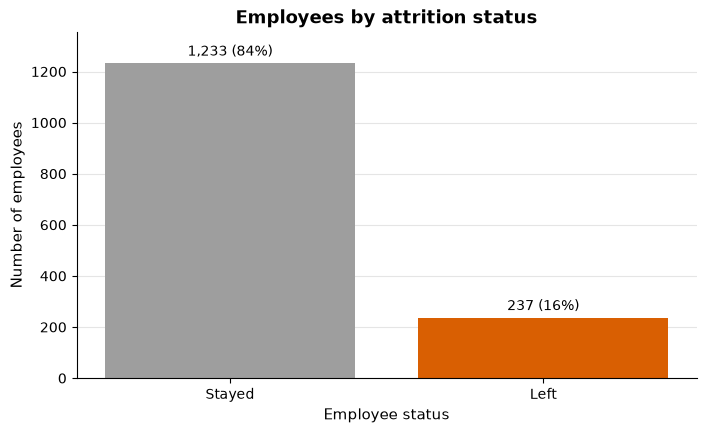

In [19]:
target_counts = employees[TARGET].map(TARGET_LABELS).value_counts()
target_shares = target_counts / target_counts.sum()

fig, ax = plt.subplots()
bars = ax.bar(
    target_counts.index,
    target_counts.values,
    color=[TARGET_COLORS[label] for label in target_counts.index],
)
ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.0%})" for count, share in zip(target_counts, target_shares)
    ],
    padding=3,
)
ax.set_title("Employees by attrition status")
ax.set_xlabel("Employee status")
ax.set_ylabel("Number of employees")
ax.set_ylim(0, target_counts.max() * 1.1)
plt.show()

Of the 1,470 employees, 237 left the company, which is 16%. A model that always predicts that an employee stays would be right 84% of the time while detecting no leaver. We keep three points in mind for later:

- The modeling will need a stratified split, metrics focused on leavers such as recall and precision, and class weights.
- With only 237 leavers, a leaving rate computed on a small group may rest on a handful of departures. We will show the group size next to every rate.
- The brief speaks of resignations, but the flag only says whether the employee left. It may also cover dismissals, ends of contract or retirements, which the data cannot separate. We treat every departure as a resignation and will mention this limit when we present the causes.

## 6. Leavers versus stayers

We now compare leavers and stayers on every explanatory variable. We plot continuous variables as boxplots, and variables with few values as leaving rates per value, which read more easily. A quantitative variable with at most 10 distinct values counts as having few values.

In [20]:
MAX_FEW_VALUES = 10

explanatory = [col for col, kind in EMPLOYEE_KINDS.items() if kind != "target"]
assert set(explanatory) <= set(COLUMN_LABELS), "a column has no label"
continuous_columns = [
    col
    for col in explanatory
    if EMPLOYEE_KINDS[col] == "quantitative"
    and employees[col].nunique() > MAX_FEW_VALUES
]
few_values_columns = [col for col in explanatory if col not in continuous_columns]

display(continuous_columns)
display(few_values_columns)

['age',
 'revenu_mensuel',
 'augmentation_salaire_precedente',
 'distance_domicile_travail',
 'annees_experience_totale',
 'annees_dans_l_entreprise',
 'annees_dans_le_poste_actuel',
 'annees_depuis_la_derniere_promotion',
 'annees_sous_responsable_actuel']

['genre',
 'heures_supplementaires',
 'statut_marital',
 'departement',
 'poste',
 'domaine_etude',
 'satisfaction_employee_environnement',
 'satisfaction_employee_nature_travail',
 'satisfaction_employee_equipe',
 'satisfaction_employee_equilibre_pro_perso',
 'note_evaluation_precedente',
 'note_evaluation_actuelle',
 'niveau_hierarchique_poste',
 'niveau_education',
 'frequence_deplacement',
 'nombre_experiences_precedentes',
 'nb_formations_suivies',
 'nombre_participation_pee']

### 6.1 Continuous variables

For continuous variables, we compare the medians of the two groups, then their full distributions.

,Stayed,Left,Gap,Gap (%)
Years in the company,6.0,3.0,-3,-50
Monthly income,5204.0,3202.0,-2002,-38
Years in the current role,3.0,2.0,-1,-33
Years under the current manager,3.0,2.0,-1,-33
Total experience (years),10.0,7.0,-3,-30
Commute distance,7.0,9.0,2,29
Age (years),36.0,32.0,-4,-11
Last salary raise (%),14.0,14.0,0,0
Years since the last promotion,1.0,1.0,0,0


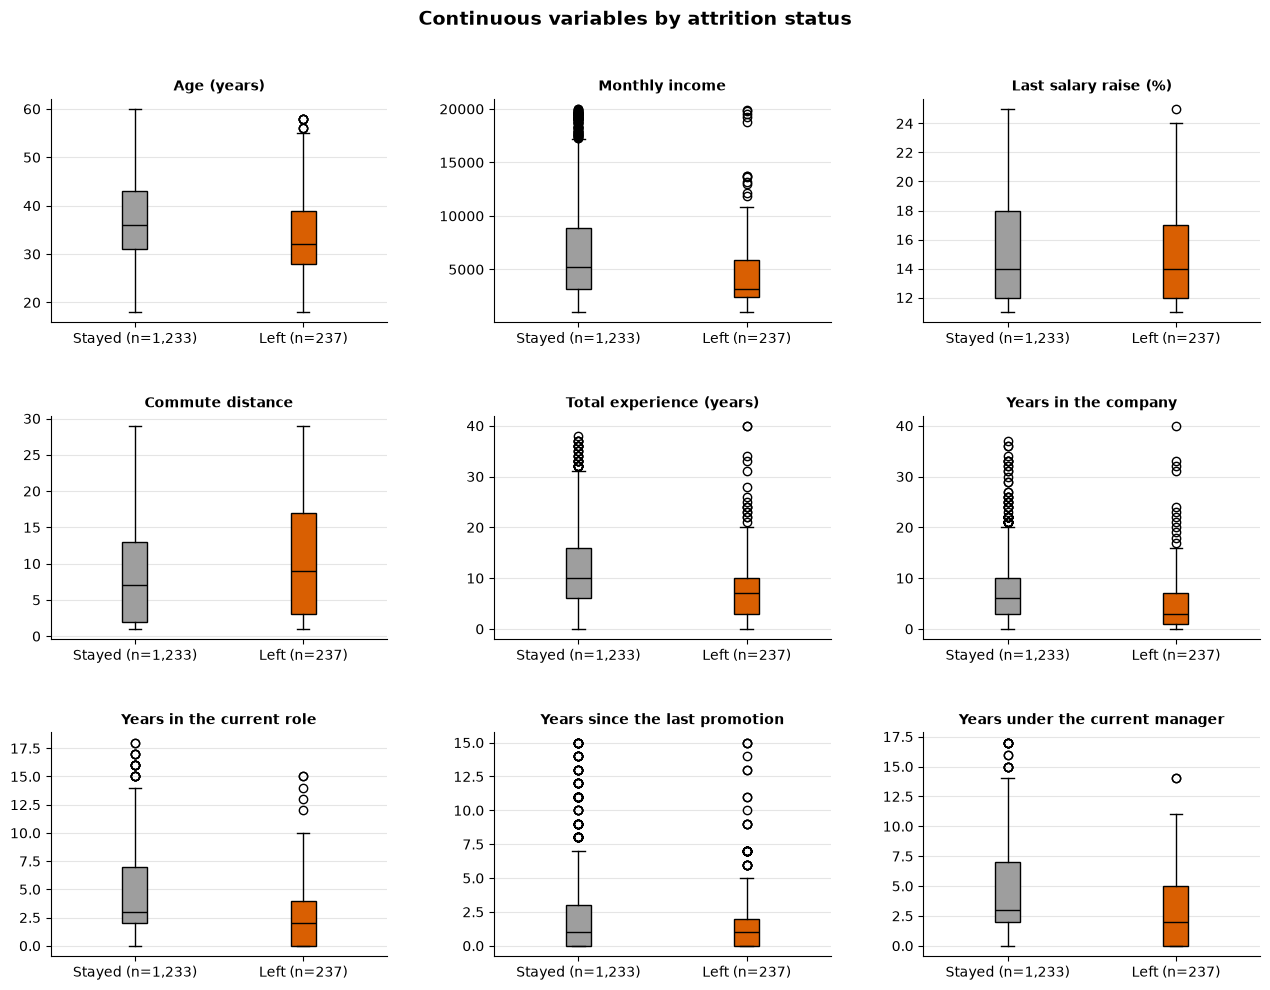

In [21]:
medians = (
    employees.groupby(employees[TARGET].map(TARGET_LABELS))[continuous_columns]
    .median()
    .T[["Stayed", "Left"]]
)
medians["Gap"] = (medians["Left"] - medians["Stayed"]).round().astype(int)
medians["Gap (%)"] = (
    ((medians["Left"] - medians["Stayed"]) / medians["Stayed"] * 100)
    .round()
    .astype(int)
)
medians = medians.loc[medians["Gap (%)"].abs().sort_values(ascending=False).index]
display(medians.rename(index=COLUMN_LABELS).rename_axis(index=None, columns=None))

plot_boxplots_by_target(
    employees, continuous_columns, "Continuous variables by attrition status"
)

Leavers differ from stayers on most continuous variables:

- They are more junior on every measure: half the seniority in the company, 3 years against 6, three fewer years of total experience, and 4 years younger.
- Their median monthly income is about 2,000 lower, 3,200 against 5,200.
- They live slightly further away, with a median commute distance of 9 against 7.
- The last salary raise and the years since the last promotion show no gap in median, so these two levers do not set leavers apart.

Seniority, experience, age and income probably describe a single junior profile rather than four separate causes. We will check how strongly they are linked when we study correlations. We read the relative gap together with the absolute one, since a one-year difference looks large on short durations.

### 6.2 Variables with few values

For each value of these variables, we compare its leaving rate with the overall rate of 16%, and we show the group size to avoid reading too much into small groups. We split the variables into three themes.

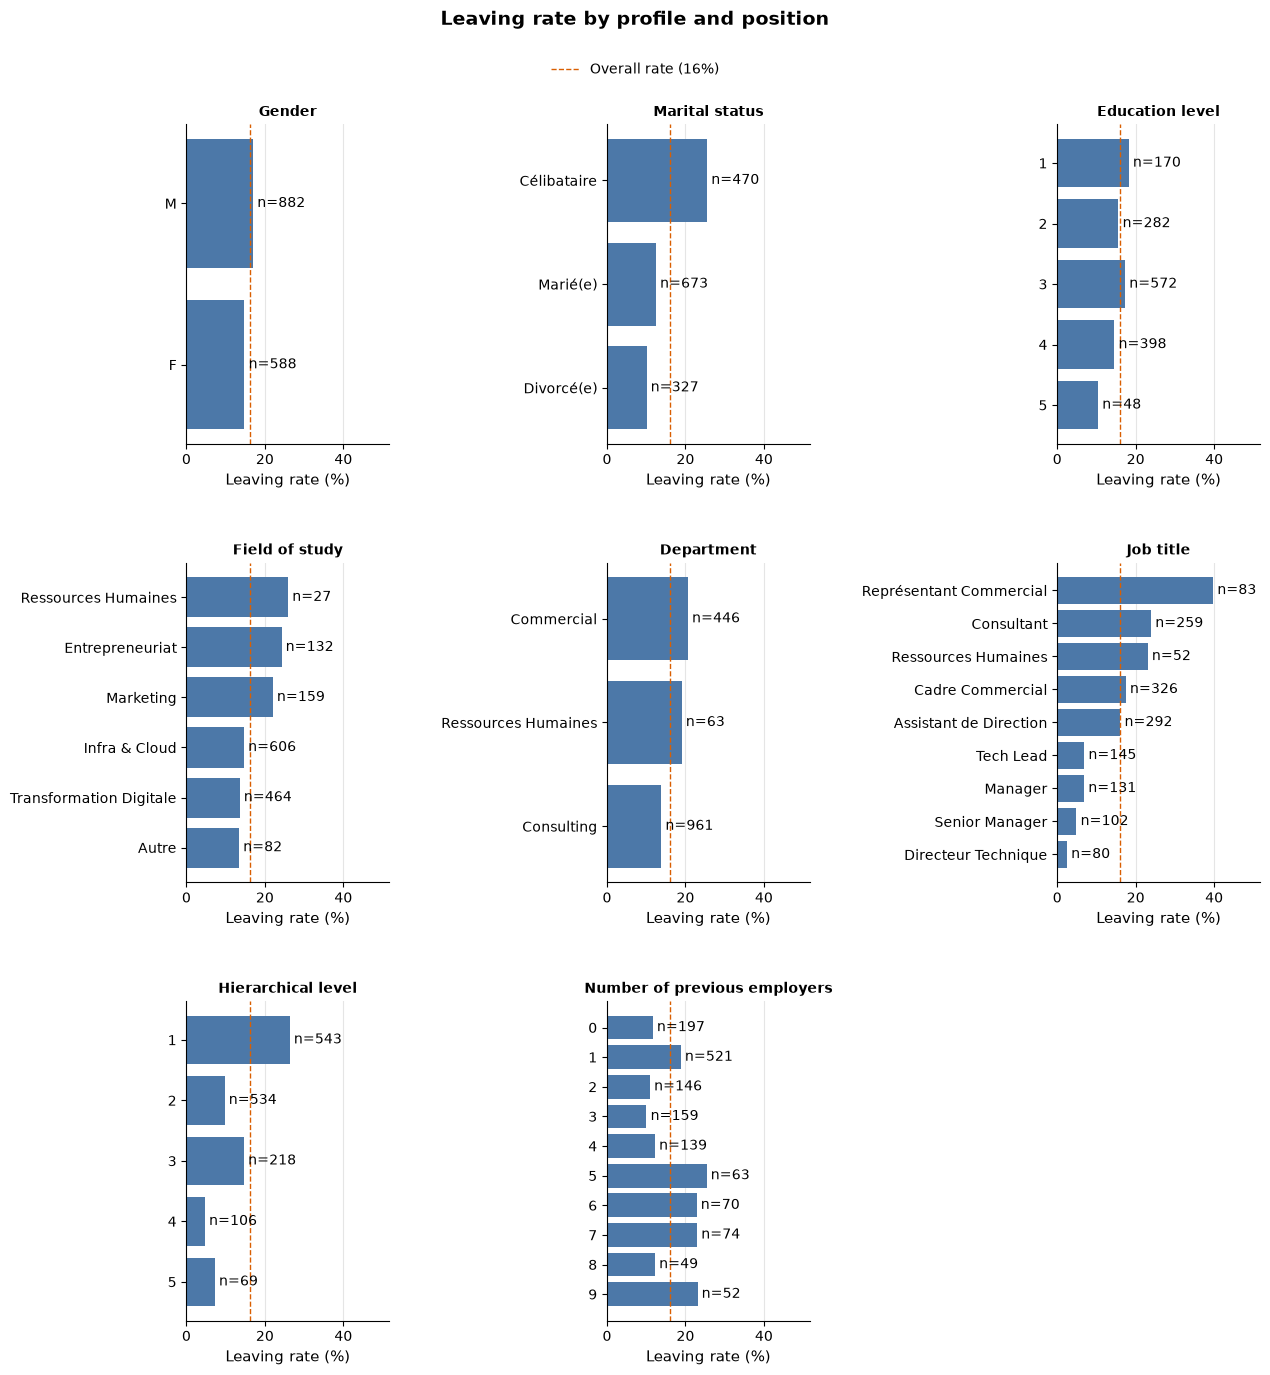

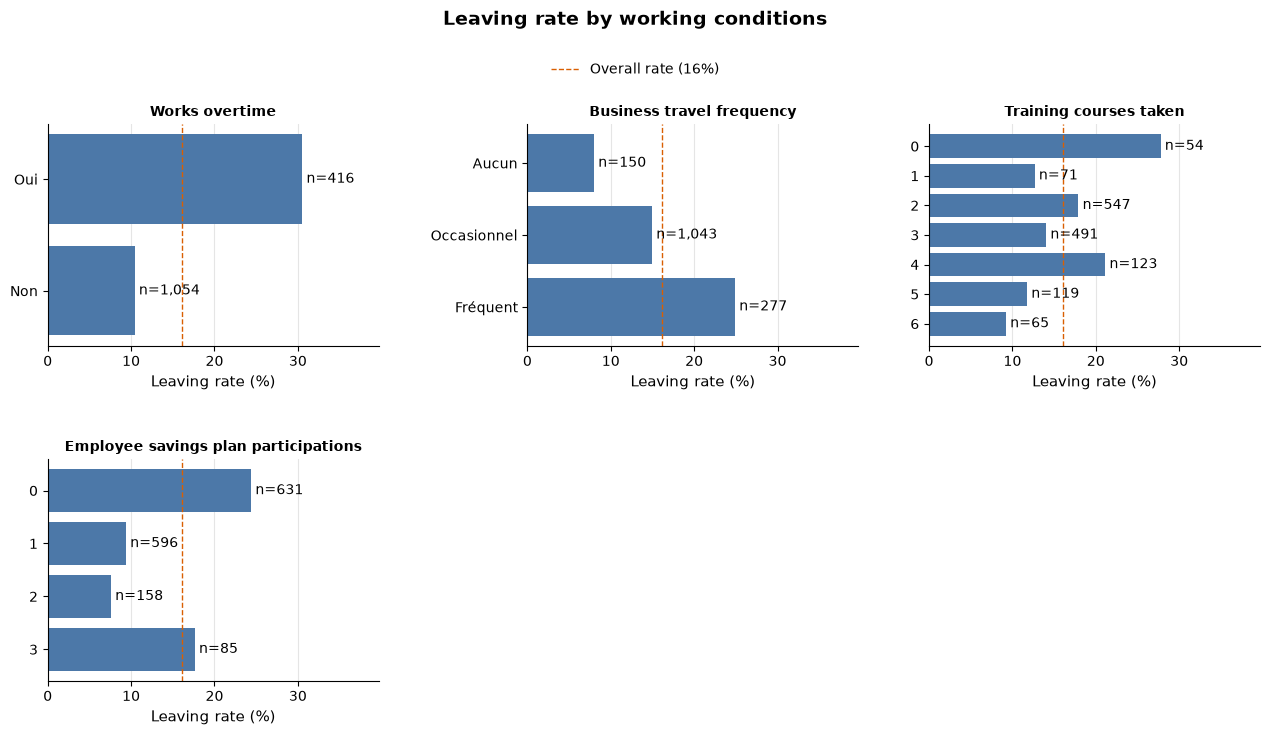

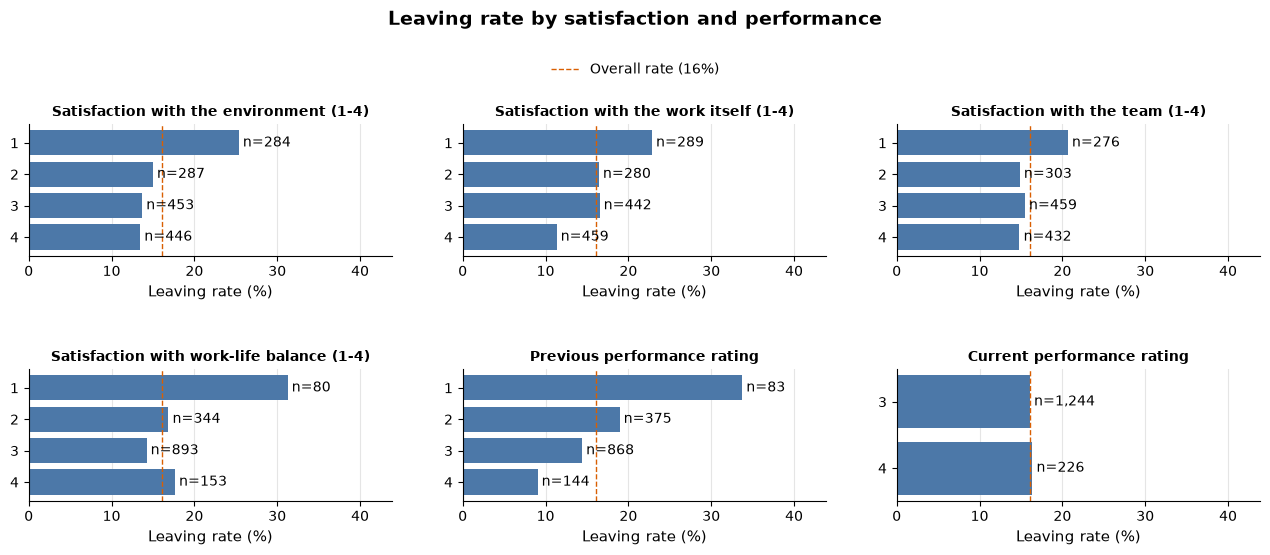

In [22]:
THEMES = {
    "Leaving rate by profile and position": [
        "genre",
        "statut_marital",
        "niveau_education",
        "domaine_etude",
        "departement",
        "poste",
        "niveau_hierarchique_poste",
        "nombre_experiences_precedentes",
    ],
    "Leaving rate by working conditions": [
        "heures_supplementaires",
        "frequence_deplacement",
        "nb_formations_suivies",
        "nombre_participation_pee",
    ],
    "Leaving rate by satisfaction and performance": [
        "satisfaction_employee_environnement",
        "satisfaction_employee_nature_travail",
        "satisfaction_employee_equipe",
        "satisfaction_employee_equilibre_pro_perso",
        "note_evaluation_precedente",
        "note_evaluation_actuelle",
    ],
}

themed_columns = [col for columns in THEMES.values() for col in columns]
assert sorted(themed_columns) == sorted(few_values_columns)

for title, columns in THEMES.items():
    plot_leaving_rate_by_value(employees, columns, title)

Several variables set leavers apart:
- Overtime is the clearest signal: 31% of employees who work overtime left, against 10% of the others.
- Junior positions leave more often. The leaving rate reaches 26% at hierarchical level 1, 40% among sales representatives (Représentant Commercial) and 24% among consultants, against 2 to 7% for managers and technical directors.
- Single employees leave more often, 26% against 10 to 12% for married or divorced employees.
- The leaving rate rises with business travel, from 8% with no travel to 25% with frequent travel.
- Employees who never joined the employee savings plan leave more often, 24% against 8 to 18% for the others.
- The lowest satisfaction score goes with a higher leaving rate on all four dimensions, from 21 to 31%. Scores from 2 to 4 differ little.
- The leaving rate falls steadily with the previous performance rating, from 34% at rating 1 to 9% at rating 4. The current rating shows no difference.

Gender, education level, number of previous employers and training courses show no clear pattern. Some high rates rest on small groups, such as the HR field of study with 7 leavers out of 27 employees, so we draw no conclusion from them. Job title, hierarchical level and marital status probably overlap with the junior profile seen in the continuous variables. We will check these links when we study correlations.

### 6.3 Summary of the differences

The brief asks for levers the company can act on, so we group the signals by what HR can do about them.

The company can act on four of them:

- Overtime: 31% of employees who work overtime left, against 10% of the others.
- Business travel: the leaving rate rises from 8% with no travel to 25% with frequent travel.
- Employee savings plan: 24% of employees who never joined it left, against 8 to 18% of the others.
- Dissatisfaction: the lowest score on any of the four satisfaction dimensions goes with a leaving rate of 21 to 31%.

Two other levers do not set leavers apart: the last salary raise and the years since the last promotion have the same median in both groups.

The other signals describe a profile to watch rather than a lever:

- Leavers are more junior: younger, with less seniority and experience, a lower income, and more often at hierarchical level 1.
- Some jobs leave more often, such as sales representatives and consultants.
- Single employees leave more often than married or divorced ones.
- The leaving rate falls steadily as the previous performance rating rises.

These are associations, not causes. Each comparison looks at one variable at a time, so two signals may come from the same employees, for instance if junior employees also work more overtime. The model and its SHAP values will show which variables still matter once the others are taken into account.

## 7. Saving the central table

We save the central table in Parquet format, which keeps the column types, and the column metadata in JSON format. The modeling notebook will load both.

In [23]:
parquet_path = PROCESSED_DIR / "employees_cleaned.parquet"
metadata_path = PROCESSED_DIR / "metadata.json"

employees.to_parquet(parquet_path)
print(
    f"Saved {employees.shape[0]} rows x {employees.shape[1]} columns to {parquet_path}"
)

metadata = {
    "employee_kinds": EMPLOYEE_KINDS,
    "column_labels": COLUMN_LABELS,
    "category_orders": CATEGORY_ORDERS,
    "target": TARGET,
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Reread the file to check that the values and the types survived the writing
pd.testing.assert_frame_equal(pd.read_parquet(parquet_path), employees)

Saved 1470 rows x 28 columns to ../data/processed/employees_cleaned.parquet
